# Pemodelan Prediksi Produksi Sayur per Kecamatan — Kabupaten Kediri

Tujuan: membuat model yang menebak **produksi (ton)** suatu sayuran di suatu kecamatan, dan mengukur **seberapa bisa diandalkan** model itu.

**Input:** hasil olahan notebook EDA sayur, yaitu `sayur_kecamatan_ada_data.csv` (di `data/processed/hortikultura/`). Jalankan notebook EDA sayur dulu sampai bagian 8 kalau file ini belum ada.

**Yang perlu diingat sebelum membaca hasil:**
- Data hanya **satu periode** (tidak ada tahun), jadi ini model **lintas wilayah** ("kalau luasnya segini, produksinya berapa?"), **bukan** ramalan tahun depan.
- Datanya kecil (±180 baris), jadi evaluasi dibuat **ketat**: tiap kecamatan diuji memakai model yang dilatih dari kecamatan *lain* (*leave-one-kecamatan-out*). Ini meniru pertanyaan sebenarnya: "bagaimana kalau ada kecamatan yang belum pernah dilihat model?"
- Target dihitung dalam **skala log** karena sebaran produksi sangat miring.

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def cari_project_root(start_path=None):
    start = os.path.abspath(start_path or os.getcwd())
    current = start

    while True:
        if (
            os.path.isdir(os.path.join(current, "data"))
            and (
                os.path.isdir(os.path.join(current, "notebooks"))
                or os.path.isdir(os.path.join(current, ".git"))
            )
        ):
            return current

        parent = os.path.dirname(current)
        if parent == current:
            break
        current = parent

    return os.path.abspath(os.path.join(start, ".."))


PROJECT_ROOT = cari_project_root()
DATA_DIR = os.path.join(PROJECT_ROOT, "data")

# folder tempat file hasil cleaning (kalau beda, tidak masalah: file dicari otomatis di seluruh data/)
FOLDER_HORTI = os.path.join(DATA_DIR, "clean", "hortikultura")
# hasil olahan notebook ini
OUT_HORTI = os.path.join(DATA_DIR, "processed", "hortikultura")
os.makedirs(OUT_HORTI, exist_ok=True)


def cari_file(nama_file, folder_utama):
    langsung = os.path.join(folder_utama, nama_file)
    if os.path.isfile(langsung):
        return langsung
    ketemu = []
    for root, _, files in os.walk(DATA_DIR):
        if nama_file in files:
            ketemu.append(os.path.join(root, nama_file))
    if not ketemu:
        raise FileNotFoundError(f"'{nama_file}' tidak ditemukan di dalam {DATA_DIR}")
    ketemu.sort(key=lambda p: ("clean" not in p.lower(), p))      # utamakan folder 'clean'
    if len(ketemu) > 1:
        print(f"Ada {len(ketemu)} file bernama {nama_file}: {ketemu} -> dipakai yang pertama")
    return ketemu[0]


print("PROJECT ROOT :", PROJECT_ROOT)
print("DATA DIR     :", DATA_DIR)
print("OUTPUT       :", OUT_HORTI)

PROJECT ROOT : path/ke/project
DATA DIR     : path/ke/project/data
OUTPUT       : path/ke/project/data/processed/hortikultura


In [2]:
try:
    from sklearn.linear_model import Ridge
    from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
    import joblib
except ImportError as e:
    raise ImportError("Library scikit-learn belum terpasang. Jalankan di terminal:  pip install scikit-learn") from e

import warnings
warnings.filterwarnings("ignore")
RS = 42        # seed supaya hasil sama setiap dijalankan

## 2. Muat Data

In [3]:
try:
    F_SAYUR = cari_file("sayur_kecamatan_ada_data.csv", OUT_HORTI)
except FileNotFoundError:
    raise FileNotFoundError("sayur_kecamatan_ada_data.csv belum ada. Jalankan dulu notebook EDA sayur sampai bagian 8 (Simpan Data Hasil Olahan).")
print("data <-", F_SAYUR)

raw = pd.read_csv(F_SAYUR, encoding="utf-8-sig")
raw.columns = raw.columns.str.strip().str.lower()

WAJIB = ["kecamatan", "komoditas", "kelompok", "luas_ha", "produksi_ton"]
hilang = [c for c in WAJIB if c not in raw.columns]
if hilang:
    raise ValueError(f"Kolom tidak ada: {hilang} | kolom di file: {raw.columns.tolist()}")

# hanya sayuran yang ada datanya (jamur dikeluarkan karena tidak berbasis lahan)
s = raw[(raw["kelompok"] == "Sayuran") & (raw["luas_ha"] > 0) & (raw["produksi_ton"] > 0)].reset_index(drop=True)
s["kecamatan"] = s["kecamatan"].astype(str).str.strip()
s["komoditas"] = s["komoditas"].astype(str).str.strip()

print(f"Baris dipakai: {len(s)} | kecamatan: {s['kecamatan'].nunique()} | komoditas: {s['komoditas'].nunique()}")
s[["kecamatan", "komoditas", "luas_ha", "produksi_ton"]].head()

data <- path/ke/project/data/processed/hortikultura/sayur_kecamatan_ada_data.csv
Baris dipakai: 180 | kecamatan: 25 | komoditas: 16


,kecamatan,komoditas,luas_ha,produksi_ton
0,Kandangan,Bawang Daun,9.00,61.40
1,Kandat,Bawang Daun,10.50,90.90
2,Kayenkidul,Bawang Daun,2.00,14.00
3,Kepung,Bawang Daun,572.00,"4,139.10"
4,Ngadiluwih,Bawang Daun,4.00,29.00


## 3. Siapkan Fitur

- **`x`** = log10(luas panen, ha)  → fitur utama
- **komoditas** → one-hot (tiap sayuran punya "produktivitas khas")
- **fitur lahan kecamatan** (opsional, kalau file lahan ada): % sawah dan % lahan pertanian bukan sawah

Fitur kecamatan tidak dipakai sebagai one-hot, karena dalam validasi per-kecamatan model tidak pernah melihat kecamatan yang sedang diuji.

In [4]:
s["y"] = np.log10(s["produksi_ton"])     # target (log10 ton)
s["x"] = np.log10(s["luas_ha"])          # fitur utama (log10 ha)

K = pd.get_dummies(s["komoditas"], prefix="kom", dtype=float)
X_luas = s[["x"]]
X_dasar = pd.concat([s[["x"]], K], axis=1)

# fitur lahan per kecamatan (opsional)
ada_lahan = False
try:
    F_LAHAN = cari_file("luas_lahan_per_kecamatan.csv", DATA_DIR)
    lahan = pd.read_csv(F_LAHAN, encoding="utf-8-sig")
    lahan.columns = lahan.columns.str.strip().str.lower()
    lahan["kecamatan"] = lahan["kecamatan"].astype(str).str.strip()
    L = lahan.set_index("kecamatan")
    fitur_lahan = pd.DataFrame({
        "persen_sawah": s["kecamatan"].map(L["luas_sawah_ha"] / L["luas_total_ha"] * 100),
        "persen_bukan_sawah": s["kecamatan"].map(L["luas_pertanian_bukan_sawah_ha"] / L["luas_total_ha"] * 100),
    })
    assert fitur_lahan.notna().all().all(), "ada nama kecamatan yang tidak cocok dengan file lahan"
    X_lahan = pd.concat([X_dasar, fitur_lahan], axis=1)
    ada_lahan = True
    print("Fitur lahan dipakai dari:", F_LAHAN)
except (FileNotFoundError, KeyError, AssertionError) as e:
    print("Fitur lahan dilewati ->", e)

print("Jumlah fitur: luas saja =", X_luas.shape[1], "| dasar =", X_dasar.shape[1], "| + lahan =", X_lahan.shape[1] if ada_lahan else "-")

Fitur lahan dipakai dari: path/ke/project/data/clean/lahan/luas_lahan_per_kecamatan.csv
Jumlah fitur: luas saja = 1 | dasar = 17 | + lahan = 19


## 4. Evaluasi: Leave-One-Kecamatan-Out

Tiap kecamatan bergantian jadi data uji, model dilatih dari kecamatan lainnya. Hasil semua tebakan dikumpulkan lalu diukur.

Metrik:
- **R² (log)**: seberapa banyak variasi produksi (skala log) yang dijelaskan. 1 = sempurna.
- **MAE (ton)**: rata-rata selisih absolut.
- **MAPE (%)**: rata-rata selisih dalam persen (peka terhadap produksi kecil).
- **Meleset (× kali)**: tebakan rata-rata salah berapa kali lipat. 1,4 berarti rata-rata hasilnya antara 1/1,4 dan 1,4 kali nilai asli.

In [5]:
kec_list = s["kecamatan"].unique()
print("Jumlah lipatan (kecamatan):", len(kec_list))

def loko(buat_model, X):
    pred = np.full(len(s), np.nan)
    for kec in kec_list:
        uji = (s["kecamatan"] == kec).values
        m = buat_model()
        m.fit(X[~uji], s["y"][~uji])
        pred[uji] = m.predict(X[uji])
    return pred

def metrik(y_log, p_log):
    yy, pp = 10 ** y_log, 10 ** p_log
    return {
        "R2 (log)": 1 - ((y_log - p_log) ** 2).sum() / ((y_log - y_log.mean()) ** 2).sum(),
        "MAE (ton)": np.abs(yy - pp).mean(),
        "MAPE (%)": (np.abs(yy - pp) / yy).mean() * 100,
        "Meleset (x kali)": 10 ** np.abs(y_log - p_log).mean(),
    }

# Baseline: luas x produktivitas median komoditas (dihitung hanya dari kecamatan lain)
pred_base = np.full(len(s), np.nan)
for kec in kec_list:
    uji = (s["kecamatan"] == kec).values
    tph = (s.loc[~uji, "produksi_ton"] / s.loc[~uji, "luas_ha"]).groupby(s.loc[~uji, "komoditas"]).median()
    pred_base[uji] = np.log10(s.loc[uji, "komoditas"].map(tph) * s.loc[uji, "luas_ha"])

hasil = {"0. Baseline (luas x median)": pred_base}

konfig = [
    ("1. Luas saja",                 lambda: Ridge(alpha=1e-6), X_luas),
    ("2. Ridge: luas + komoditas",   lambda: Ridge(alpha=1.0), X_dasar),
    ("4. Random Forest",             lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RS, n_jobs=-1), X_dasar),
    ("6. Gradient Boosting",         lambda: GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=RS), X_dasar),
]
if ada_lahan:
    konfig += [
        ("3. Ridge + lahan",         lambda: Ridge(alpha=1.0), X_lahan),
        ("5. Random Forest + lahan", lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RS, n_jobs=-1), X_lahan),
        ("7. Gradient Boosting + lahan", lambda: GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=RS), X_lahan),
    ]
konfig.sort(key=lambda t: t[0])

for nama, buat, X in konfig:
    hasil[nama] = loko(buat, X)

tabel = pd.DataFrame({nama: metrik(s["y"].values[~np.isnan(p)], p[~np.isnan(p)]) for nama, p in hasil.items()}).T
tabel["Baris diuji"] = [int((~np.isnan(p)).sum()) for p in hasil.values()]
tabel

Jumlah lipatan (kecamatan): 25


,R2 (log),MAE (ton),MAPE (%),Meleset (x kali),Baris diuji
0. Baseline (luas x median),0.95,272.90,36.56,1.38,180
1. Luas saja,0.90,378.74,51.52,1.59,180
2. Ridge: luas + komoditas,0.95,296.21,35.92,1.39,180
3. Ridge + lahan,0.95,323.34,35.43,1.39,180
4. Random Forest,0.91,396.52,50.71,1.56,180
5. Random Forest + lahan,0.90,426.08,52.00,1.59,180
6. Gradient Boosting,0.94,289.88,39.65,1.42,180
7. Gradient Boosting + lahan,0.94,346.84,39.92,1.42,180


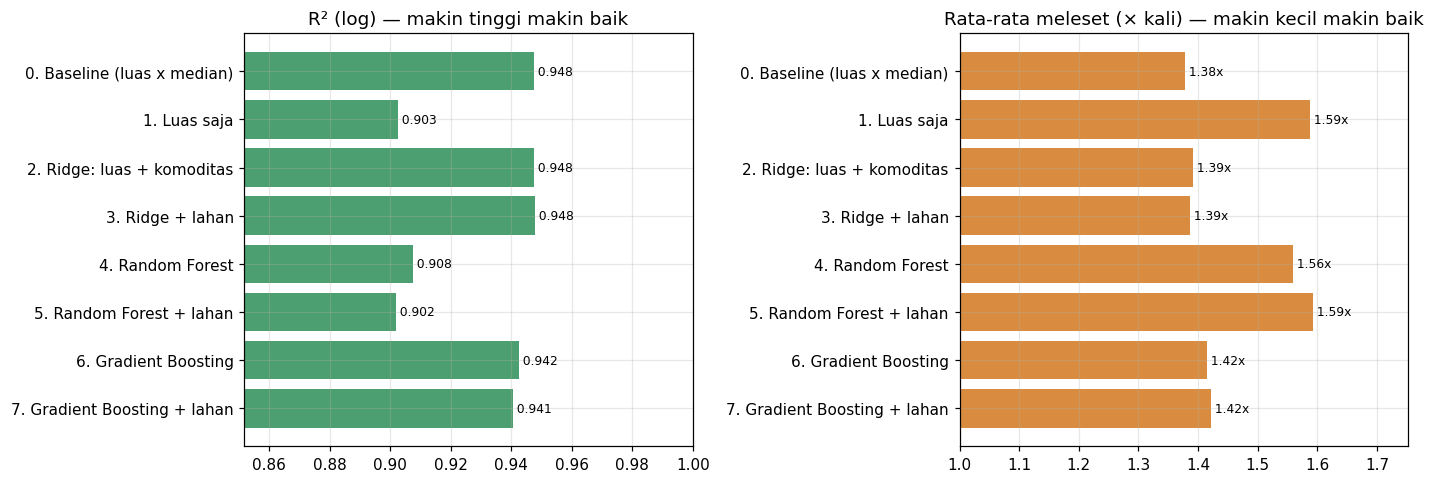

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
nama_pendek = [n.split(". ", 1)[0] + ". " + n.split(". ", 1)[1][:28] for n in tabel.index]
ax[0].barh(nama_pendek[::-1], tabel["R2 (log)"].values[::-1], color="#4c9f70")
for y, v in enumerate(tabel["R2 (log)"].values[::-1]):
    ax[0].text(v, y, f" {v:.3f}", va="center", fontsize=8)
ax[0].set_xlim(tabel["R2 (log)"].min() - 0.05, 1.0)
ax[0].set_title("R² (log) — makin tinggi makin baik")
ax[1].barh(nama_pendek[::-1], tabel["Meleset (x kali)"].values[::-1], color="#d98c3f")
for y, v in enumerate(tabel["Meleset (x kali)"].values[::-1]):
    ax[1].text(v, y, f" {v:.2f}x", va="center", fontsize=8)
ax[1].set_xlim(1, tabel["Meleset (x kali)"].max() * 1.1)
ax[1].set_title("Rata-rata meleset (× kali) — makin kecil makin baik")
plt.tight_layout(); plt.show()

### Memilih model

Aturan yang dipakai: ambil model **paling sederhana** yang hasilnya hanya selisih ≤ 0,005 dari R² terbaik. Pada data sekecil ini, model yang lebih rumit belum tentu lebih baik (mudah menghafal), sedangkan model sederhana lebih mudah dijelaskan ke Dinas.

In [7]:
tabel_model = tabel.drop(index=[n for n in tabel.index if n.startswith("0.")])
r2_terbaik = tabel_model["R2 (log)"].max()
kandidat = tabel_model[tabel_model["R2 (log)"] >= r2_terbaik - 0.005]
nama_pilih = sorted(kandidat.index)[0]          # nomor terkecil = paling sederhana

print("R2 (log) terbaik:", round(r2_terbaik, 3))
print("Model terpilih  :", nama_pilih)
print("Hasilnya        :", tabel.loc[nama_pilih, ["R2 (log)", "MAE (ton)", "MAPE (%)", "Meleset (x kali)"]].round(3).to_dict())
print("Baseline        :", tabel.iloc[0][["R2 (log)", "MAE (ton)", "MAPE (%)", "Meleset (x kali)"]].round(3).to_dict())

R2 (log) terbaik: 0.948
Model terpilih  : 2. Ridge: luas + komoditas
Hasilnya        : {'R2 (log)': 0.948, 'MAE (ton)': 296.208, 'MAPE (%)': 35.925, 'Meleset (x kali)': 1.392}
Baseline        : {'R2 (log)': 0.948, 'MAE (ton)': 272.9, 'MAPE (%)': 36.565, 'Meleset (x kali)': 1.379}


## 5. Di Mana Model Meleset?

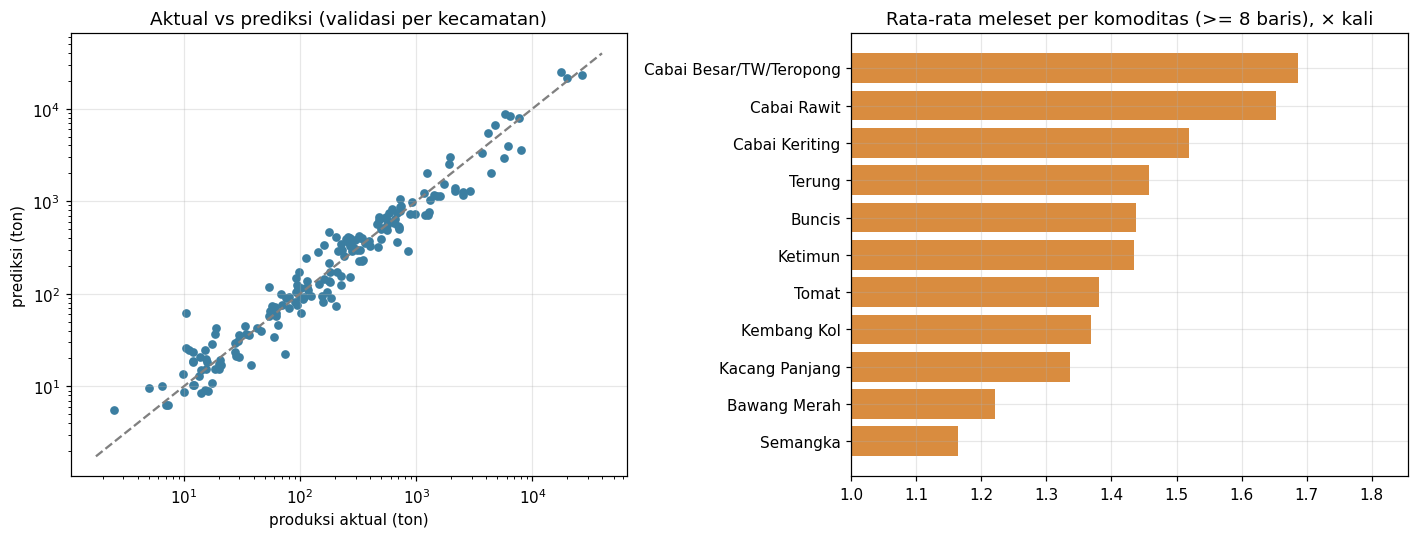

In [8]:
pred_log = hasil[nama_pilih]
s["pred_ton"] = 10 ** pred_log
s["rasio"] = s["pred_ton"] / s["produksi_ton"]         # >1 = prediksi kelebihan, <1 = kurang
s["meleset_x"] = 10 ** np.abs(pred_log - s["y"])

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(s["produksi_ton"], s["pred_ton"], s=22, color="#3b7ea1")
lim = [s[["produksi_ton", "pred_ton"]].min().min() * 0.7, s[["produksi_ton", "pred_ton"]].max().max() * 1.5]
ax[0].plot(lim, lim, "--", color="gray")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("produksi aktual (ton)"); ax[0].set_ylabel("prediksi (ton)")
ax[0].set_title("Aktual vs prediksi (validasi per kecamatan)")

n_kom = s.groupby("komoditas").size()
per_kom = s[s["komoditas"].isin(n_kom[n_kom >= 8].index)].groupby("komoditas")["meleset_x"].mean().sort_values()
ax[1].barh(per_kom.index, per_kom.values, color="#d98c3f")
ax[1].set_xlim(1, per_kom.max() * 1.1)
ax[1].set_title("Rata-rata meleset per komoditas (>= 8 baris), × kali")
plt.tight_layout(); plt.show()

In [9]:
print("8 tebakan paling meleset:")
s.sort_values("meleset_x", ascending=False).head(8)[["kecamatan", "komoditas", "luas_ha", "produksi_ton", "pred_ton", "rasio", "meleset_x"]]

8 tebakan paling meleset:


,kecamatan,komoditas,luas_ha,produksi_ton,pred_ton,rasio,meleset_x
67,Mojo,Cabai Rawit,6.00,10.40,62.33,5.99,5.99
99,Purwoasri,Kangkung,1.00,74.50,22.40,0.30,3.33
151,Kras,Terung,12.00,841.20,286.26,0.34,2.94
97,Kayenkidul,Kangkung,3.00,203.10,73.17,0.36,2.78
98,Ngadiluwih,Kangkung,11.00,175.70,466.52,2.66,2.66
45,Tarokan,Cabai Besar/TW/Teropong,2.00,10.40,26.17,2.52,2.52
55,Ringinrejo,Cabai Keriting,125.00,"2,910.10","1,287.22",0.44,2.26
7,Banyakan,Bawang Merah,6.00,19.00,42.75,2.25,2.25


Baris yang paling meleset biasanya adalah baris yang produktivitasnya **sangat berbeda** dari kecamatan lain (dan sebagian sudah ditandai ekstrem di notebook EDA, mis. Mojo–Cabai Rawit). Jadi sebagian "kesalahan model" sebenarnya bisa jadi **kesalahan data** yang perlu dikonfirmasi ke sumber.

## 6. Interpretasi Model Sederhana

In [10]:
ridge = Ridge(alpha=1.0).fit(X_dasar, s["y"])
elastisitas = ridge.coef_[0]
print(f"Elastisitas luas: {elastisitas:.3f}")
print("  -> luas panen naik 10% => produksi naik sekitar", f"{((1.1 ** elastisitas) - 1) * 100:.1f}%", "(nilai 1,0 = produksi tepat sebanding dengan luas)\n")

# produksi yang diharapkan untuk 1 hektar, per komoditas
nama_kom = [c.replace("kom_", "") for c in X_dasar.columns[1:]]
satu_ha = pd.DataFrame({
    "ton per 1 ha": 10 ** (ridge.intercept_ + ridge.coef_[1:]),
    "jumlah baris data": [int((s["komoditas"] == k).sum()) for k in nama_kom],
}, index=nama_kom).sort_values("ton per 1 ha", ascending=False)
print("Produksi yang diharapkan untuk 1 hektar (ton). Komoditas dengan < 5 baris data kurang bisa dipercaya:")
satu_ha.round(1)

Elastisitas luas: 1.029
  -> luas panen naik 10% => produksi naik sekitar 10.3% (nilai 1,0 = produksi tepat sebanding dengan luas)

Produksi yang diharapkan untuk 1 hektar (ton). Komoditas dengan < 5 baris data kurang bisa dipercaya:


,ton per 1 ha,jumlah baris data
Kangkung,30.60,3
Terung,23.40,19
Ketimun,18.00,17
Tomat,17.50,17
Semangka,15.50,8
Melon,13.70,4
Cabai Besar/TW/Teropong,11.60,11
Kembang Kol,10.70,8
Buncis,10.50,12
Cabai Keriting,9.70,10


## 7. Seberapa Pasti Tebakannya? (Interval)

Dari galat validasi, dihitung berapa kali lipat tebakan biasanya meleset pada **80% kasus**. Ini yang dipakai untuk membuat rentang prediksi di dasbor (Aktual → Prediksi → **Rentang**).

In [11]:
galat = np.abs(pred_log - s["y"].values)
FAKTOR_80 = float(10 ** np.quantile(galat, 0.80))
print(f"Pada 80% kasus, tebakan meleset paling banyak {FAKTOR_80:.2f}x")
print("  artinya rentang prediksi = [prediksi / %.2f , prediksi x %.2f]" % (FAKTOR_80, FAKTOR_80))
print("(dihitung dari galat validasi yang sama, jadi untuk data baru angkanya bisa sedikit berbeda)")

Pada 80% kasus, tebakan meleset paling banyak 1.66x
  artinya rentang prediksi = [prediksi / 1.66 , prediksi x 1.66]
(dihitung dari galat validasi yang sama, jadi untuk data baru angkanya bisa sedikit berbeda)


## 8. Model Akhir & Fungsi Prediksi

In [12]:
buat_akhir, X_akhir = next((b, X) for n, b, X in konfig if n == nama_pilih)
model_akhir = buat_akhir().fit(X_akhir, s["y"])
kolom_model = X_akhir.columns.tolist()

def prediksi(komoditas, luas_ha, kecamatan=None):
    """Prediksi produksi (ton) + rentang 80%. Contoh: prediksi("Tomat", 20)"""
    baris = pd.DataFrame(0.0, index=[0], columns=kolom_model)
    baris.loc[0, "x"] = np.log10(luas_ha)
    kol = "kom_" + komoditas
    if kol not in baris.columns:
        raise ValueError(f"Komoditas '{komoditas}' tidak dikenal. Pilihan: {sorted(c[4:] for c in kolom_model if c.startswith('kom_'))}")
    baris.loc[0, kol] = 1.0
    if "persen_sawah" in kolom_model:
        if kecamatan is None or kecamatan not in L.index:
            raise ValueError("Model ini memakai fitur lahan: isi argumen kecamatan= dengan nama kecamatan yang valid")
        baris.loc[0, "persen_sawah"] = L.loc[kecamatan, "luas_sawah_ha"] / L.loc[kecamatan, "luas_total_ha"] * 100
        baris.loc[0, "persen_bukan_sawah"] = L.loc[kecamatan, "luas_pertanian_bukan_sawah_ha"] / L.loc[kecamatan, "luas_total_ha"] * 100
    p = 10 ** model_akhir.predict(baris)[0]
    p = float(p)
    return {"komoditas": komoditas, "luas_ha": luas_ha, "prediksi_ton": round(p, 1),
            "rentang_80%": (round(p / FAKTOR_80, 1), round(p * FAKTOR_80, 1))}

contoh_kec = s["kecamatan"].iloc[0] if "persen_sawah" in kolom_model else None
for kom, luas in [("Cabai Rawit", 100), ("Tomat", 20), ("Terung", 10)]:
    print(prediksi(kom, luas, contoh_kec))

{'komoditas': 'Cabai Rawit', 'luas_ha': 100, 'prediksi_ton': 1038.5, 'rentang_80%': (626.2, 1722.3)}
{'komoditas': 'Tomat', 'luas_ha': 20, 'prediksi_ton': 383.2, 'rentang_80%': (231.0, 635.5)}
{'komoditas': 'Terung', 'luas_ha': 10, 'prediksi_ton': 250.5, 'rentang_80%': (151.0, 415.4)}


## 9. Simpan Hasil

In [13]:
tabel.to_csv(os.path.join(OUT_HORTI, "model_sayur_hasil_validasi.csv"))
s[["kecamatan", "komoditas", "luas_ha", "produksi_ton", "pred_ton", "rasio", "meleset_x"]].to_csv(
    os.path.join(OUT_HORTI, "model_sayur_prediksi_validasi.csv"), index=False)
joblib.dump({"model": model_akhir, "kolom": kolom_model, "nama_model": nama_pilih, "faktor_80": FAKTOR_80},
            os.path.join(OUT_HORTI, "model_sayur_terpilih.joblib"))

print("Tersimpan di:", OUT_HORTI)
for f in sorted(os.listdir(OUT_HORTI)):
    if f.startswith("model_sayur"):
        print(" -", f)

Tersimpan di: path/ke/project/data/processed/hortikultura
 - model_sayur_hasil_validasi.csv
 - model_sayur_prediksi_validasi.csv
 - model_sayur_terpilih.joblib


## 10. Kesimpulan

**Hasil utama**
- Dengan validasi ketat per kecamatan (25 kecamatan, 180 baris), model terpilih **Ridge log-log: luas panen + komoditas** mencapai **R² (log) ±0,95**, tebakan rata-rata meleset **±1,4 kali**, MAPE **±36%**, dan MAE **±296 ton**.
- **Model yang lebih rumit tidak lebih baik.** Random Forest (R² ±0,91) dan Gradient Boosting (±0,94) tidak mengalahkan model sederhana. **Fitur lahan kecamatan juga tidak membantu** (R² tetap ±0,95, MAE malah naik). Baseline "luas × produktivitas median komoditas" setara (R² ±0,95, MAE bahkan sedikit lebih kecil, ±273 ton).
- **Luas panen adalah penjelas utama:** hanya dengan luas R² ±0,90; menambah jenis komoditas naik ke ±0,95. Elastisitas luas ±1,03, artinya produksi hampir **sebanding** dengan luas panen.
- **Rentang prediksi:** pada 80% kasus tebakan meleset paling banyak ±1,66 kali. Ini bisa dipakai sebagai rentang di fitur Prediksi dasbor.

**Yang perlu diwaspadai**
- Data hanya **satu periode** dan kecil (180 baris, 25 kecamatan). Ini model **lintas wilayah**, bukan ramalan tahun depan, dan hasilnya bisa berubah dengan data baru.
- Prediksi hanya berlaku kalau **luas panen sudah diketahui**. Model untuk memprediksi luas panen itu sendiri belum bisa dibuat tanpa data beberapa tahun.
- Tebakan yang paling meleset berasal dari baris yang produktivitasnya ekstrem atau datanya sedikit (Mojo–Cabai Rawit, Kras–Terung, Kangkung). Sebagian mungkin salah catat, jadi perlu dikonfirmasi ke sumber.
- Komoditas dengan data sangat sedikit (Kangkung, Bayam, Melon) prediksinya tidak bisa diandalkan.

**Langkah berikutnya**
1. Konfirmasi baris ekstrem ke yang membersihkan data, lalu ulangi evaluasi untuk melihat apakah hasilnya naik.
2. Kalau ada data **multi-tahun**: tambahkan forecast (ARIMA, Exponential Smoothing, Prophet) dan bandingkan dengan model ini.
3. Pakai model ini untuk fitur **Prediksi** (dengan rentangnya), dan buat clustering kecamatan untuk fitur **Pemetaan**.